<div style="
background: linear-gradient(135deg,#0F172A,#1E3A8A);
padding:30px;
border-radius:18px;
color:white;
text-align:center;
box-shadow:0px 4px 20px rgba(0,0,0,0.25);">

<h1 style="margin:0;font-size:38px;">
🎥 Movie Genre Time Series Forecasting
</h1>

<h3 style="margin-top:10px;color:#CBD5E1;">
Exploratory Data Analysis of Time Series
</h3>

<hr style="width:70%;border:1px solid rgba(255,255,255,0.2);">

<div style="
display:flex;
justify-content:space-around;
flex-wrap:wrap;
margin-top:20px;">

<div style="
background:white;
color:#111827;
padding:15px;
margin:10px;
border-radius:12px;
width:220px;
font-weight:bold;">
📅 Dataset Range<br>
1996 - 2022
</div>

<div style="
background:white;
color:#111827;
padding:15px;
margin:10px;
border-radius:12px;
width:220px;
font-weight:bold;">
📈 Time Frequency<br>
Monthly Data
</div>

<div style="
background:white;
color:#111827;
padding:15px;
margin:10px;
border-radius:12px;
width:220px;
font-weight:bold;">
🤖 Forecasting Models<br>
Naive • ARIMA • SARIMA • LSTM
</div>

</div>

<p style="
margin-top:25px;
font-size:16px;
color:#E2E8F0;">

This notebook presents an exploratory data analysis of movie genre popularity time series componenets and visualisation

</p>

</div>

In [2]:
# Environment Setup (configuration)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.filters.hp_filter import hpfilter
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import warnings

warnings.filterwarnings("ignore")

# Configure consistent visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11

print("Environment configured successfully.")

Environment configured successfully.


<div style="
background:#1F2937;
padding:12px;
border-left:8px solid #3bd7f6;
border-radius:8px;
color:white;
font-size:24px;
font-weight:bold;">

STEP 1 - Loading Data 💾

</div>

In [3]:
print("\nLoading extracted time series datasets...\n")

counts_path = "../data/processed/monthly_genre_raw_counts.csv"
share_path = "../data/processed/monthly_genre_market_share.csv"

df_counts = pd.read_csv(counts_path, index_col='date', parse_dates=True)
df_share = pd.read_csv(share_path, index_col='date', parse_dates=True)

# Select 7 core genres covering major film types
target_genres = ['Action', 'Adventure', 'Comedy', 'Drama', 'Romance', 'Sci-Fi', 'Thriller']

data_counts = df_counts[target_genres].dropna()
data_share = df_share[target_genres].dropna()

print(f"Data spans {len(data_share)} monthly observations from {data_share.index.min().strftime('%Y-%m')} to {data_share.index.max().strftime('%Y-%m')}.")
print(f"Selected {len(target_genres)} target genres: {target_genres}")


Loading extracted time series datasets...

Data spans 323 monthly observations from 1996-01 to 2022-12.
Selected 7 target genres: ['Action', 'Adventure', 'Comedy', 'Drama', 'Romance', 'Sci-Fi', 'Thriller']


In [4]:
print(f"Dataset Dimensions: {data_share.shape}\n")
data_share.head(7)

Dataset Dimensions: (323, 7)



,Action,Adventure,Comedy,Drama,Romance,Sci-Fi,Thriller
date,,,,,,,
1996-01-01,6.024096,8.433735,25.301205,21.686747,12.048193,4.819277,21.686747
1996-02-01,9.270705,7.169345,19.777503,29.913473,15.698393,2.595797,15.574784
1996-03-01,14.077369,10.360944,19.162115,25.378681,11.335098,5.687257,13.998536
1996-04-01,14.931128,11.420962,18.966031,23.541571,10.590129,5.510723,15.039455
1996-05-01,15.356014,11.341320,18.313767,22.298782,10.205984,5.761515,16.722617
1996-06-01,15.263771,10.865568,19.111927,21.735688,11.117335,5.561636,16.344074
1996-07-01,15.685034,10.855501,18.687932,21.163563,11.049902,5.964990,16.593079


<div style="
background:#1F2937;
padding:12px;
border-left:8px solid #3bd7f6;
border-radius:8px;
color:white;
font-size:24px;
font-weight:bold;">

STEP 2 - Missing data check and Interpolation 〽️

</div>

In [5]:
# Set monthly frequency & check missing months
df_counts = df_counts.loc["1997-01-01":"2022-12-01"].asfreq("MS")
df_share  = df_share.loc["1997-01-01":"2022-12-01"].asfreq("MS")

missing = df_share.index[df_share.isna().any(axis=1)]
print("Missing months:", [d.strftime("%Y-%m") for d in missing])
print(f"Data spans {len(df_share)} monthly observations from {df_share.index.min().strftime('%Y-%m')} to {df_share.index.max().strftime('%Y-%m')}.")

Missing months: ['1997-08']
Data spans 312 monthly observations from 1997-01 to 2022-12.


`time series had a missing month (1997-08) hence we will interpolate using time interpolation as per model suitable format`

In [7]:
# Impute time series with missing data
df_counts = df_counts.interpolate().round()
df_share  = df_share.interpolate()

# chcek again
missing = df_share.index[df_share.isna().any(axis=1)]
print("Missing months:", [d.strftime("%Y-%m") for d in missing])
print(f"Data spans {len(df_share)} monthly observations from {df_share.index.min().strftime('%Y-%m')} to {df_share.index.max().strftime('%Y-%m')}.")

Missing months: []
Data spans 312 monthly observations from 1997-01 to 2022-12.


<div style="
background:#1F2937;
padding:12px;
border-left:8px solid #3bd7f6;
border-radius:8px;
color:white;
font-size:24px;
font-weight:bold;">

STEP 3 - Adressing Multicollinearity Problem 〽️

</div>


Evaluating cross-genre correlation matrices...


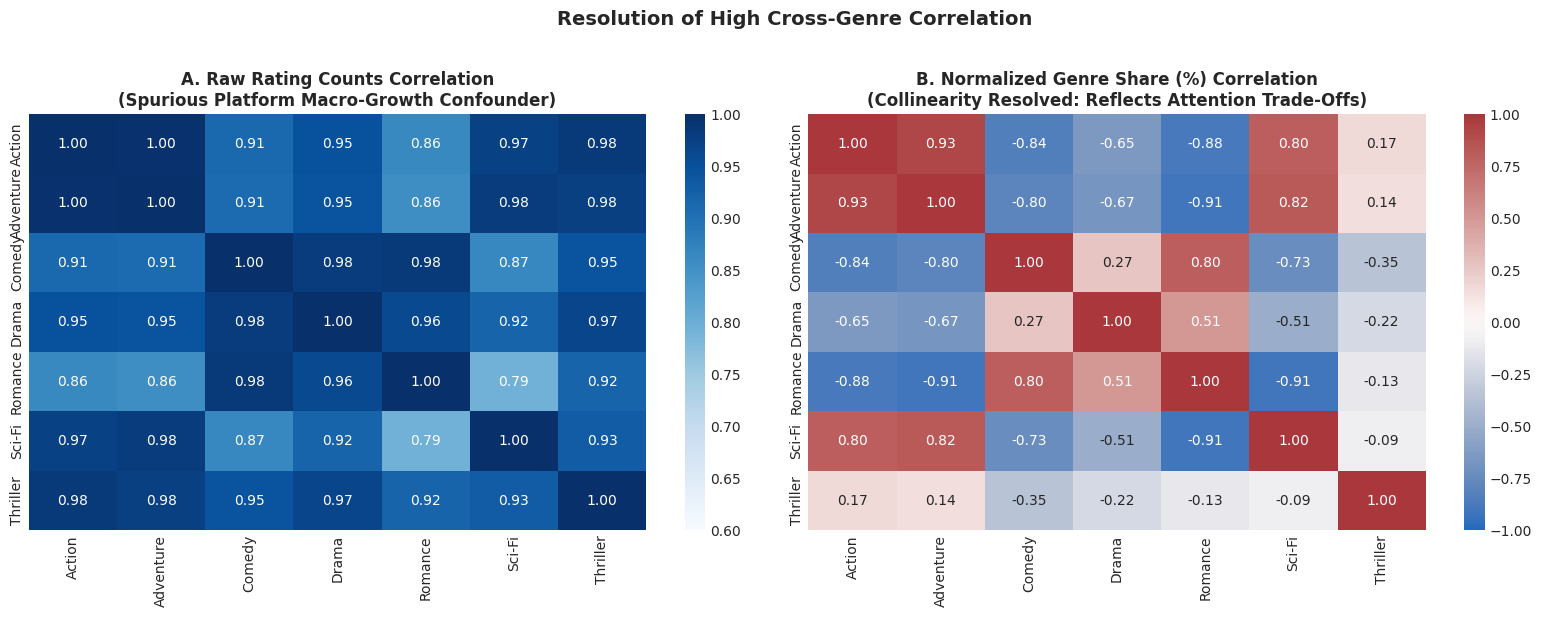

In [8]:
print("\nEvaluating cross-genre correlation matrices...")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 2A. Raw Counts Correlation Heatmap
corr_raw = data_counts.corr()
sns.heatmap(corr_raw, annot=True, fmt=".2f", cmap='Blues', ax=axes[0], vmin=0.6, vmax=1.0, cbar=True)
axes[0].set_title("A. Raw Rating Counts Correlation\n(Spurious Platform Macro-Growth Confounder)")

# 2B. Normalized popularity Share Correlation Heatmap
corr_share = data_share.corr()
sns.heatmap(corr_share, annot=True, fmt=".2f", cmap='vlag', ax=axes[1], vmin=-1.0, vmax=1.0, cbar=True)
axes[1].set_title("B. Normalized Genre Share (%) Correlation\n(Collinearity Resolved: Reflects Attention Trade-Offs)")

plt.suptitle("Resolution of High Cross-Genre Correlation", y=1.02, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

<text>
------------------------------------------------------------------------------ <br>
STEP 3: ADDRESSING CROSS-GENRE COLLINEARITY (RAW COUNTS VS. MARKET SHARE)<br>
------------------------------------------------------------------------------<br>
Reason for using Relative Share:<br>
Raw rating volumes exhibit spurious near-perfect correlation (r > ~0.9) because
platform growth causes all genres to surge concurrently.<br> 
Converting to Relative Market Share (%) normalizes by total monthly activity, capturing
genuine audience attention trade-offs and resolving multicollinearity.<br>
------------------------------------------------------------------------------<br>
</text>

`The relative share correlation matrix shows ACTION, ADVENTURE, SCI-FI have high positive correlation among each other <br> whereas a strong negative correlation with COMEDY and ROMANCE genres respectively`

<div style="
background:#1F2937;
padding:12px;
border-left:8px solid #3bd7f6;
border-radius:8px;
color:white;
font-size:24px;
font-weight:bold;">

STEP 4 - Time Series Visualisations 📈

</div>


Visualizing long-term trends (y_t vs. Time graph) of all genres...


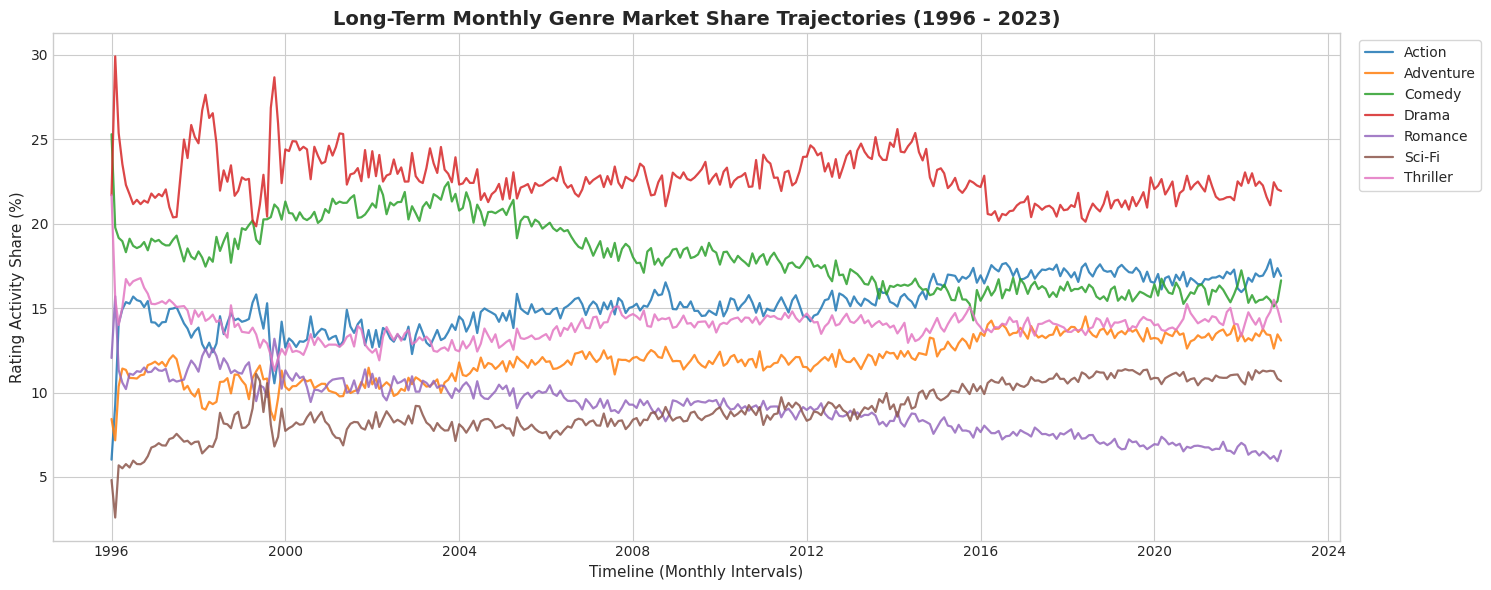

In [9]:
print("\nVisualizing long-term trends (y_t vs. Time graph) of all genres...")

# Combined Multi-Line Trajectory
plt.figure(figsize=(15, 6))
colors = sns.color_palette("tab10", len(target_genres))

for idx, g in enumerate(target_genres):
    plt.plot(data_share.index, data_share[g], label=g, color=colors[idx], lw=1.6, alpha=0.85)

plt.title("Long-Term Monthly Genre Market Share Trajectories (1996 - 2023)", fontsize=14, fontweight='bold')
plt.xlabel("Timeline (Monthly Intervals)")
plt.ylabel("Rating Activity Share (%)")
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

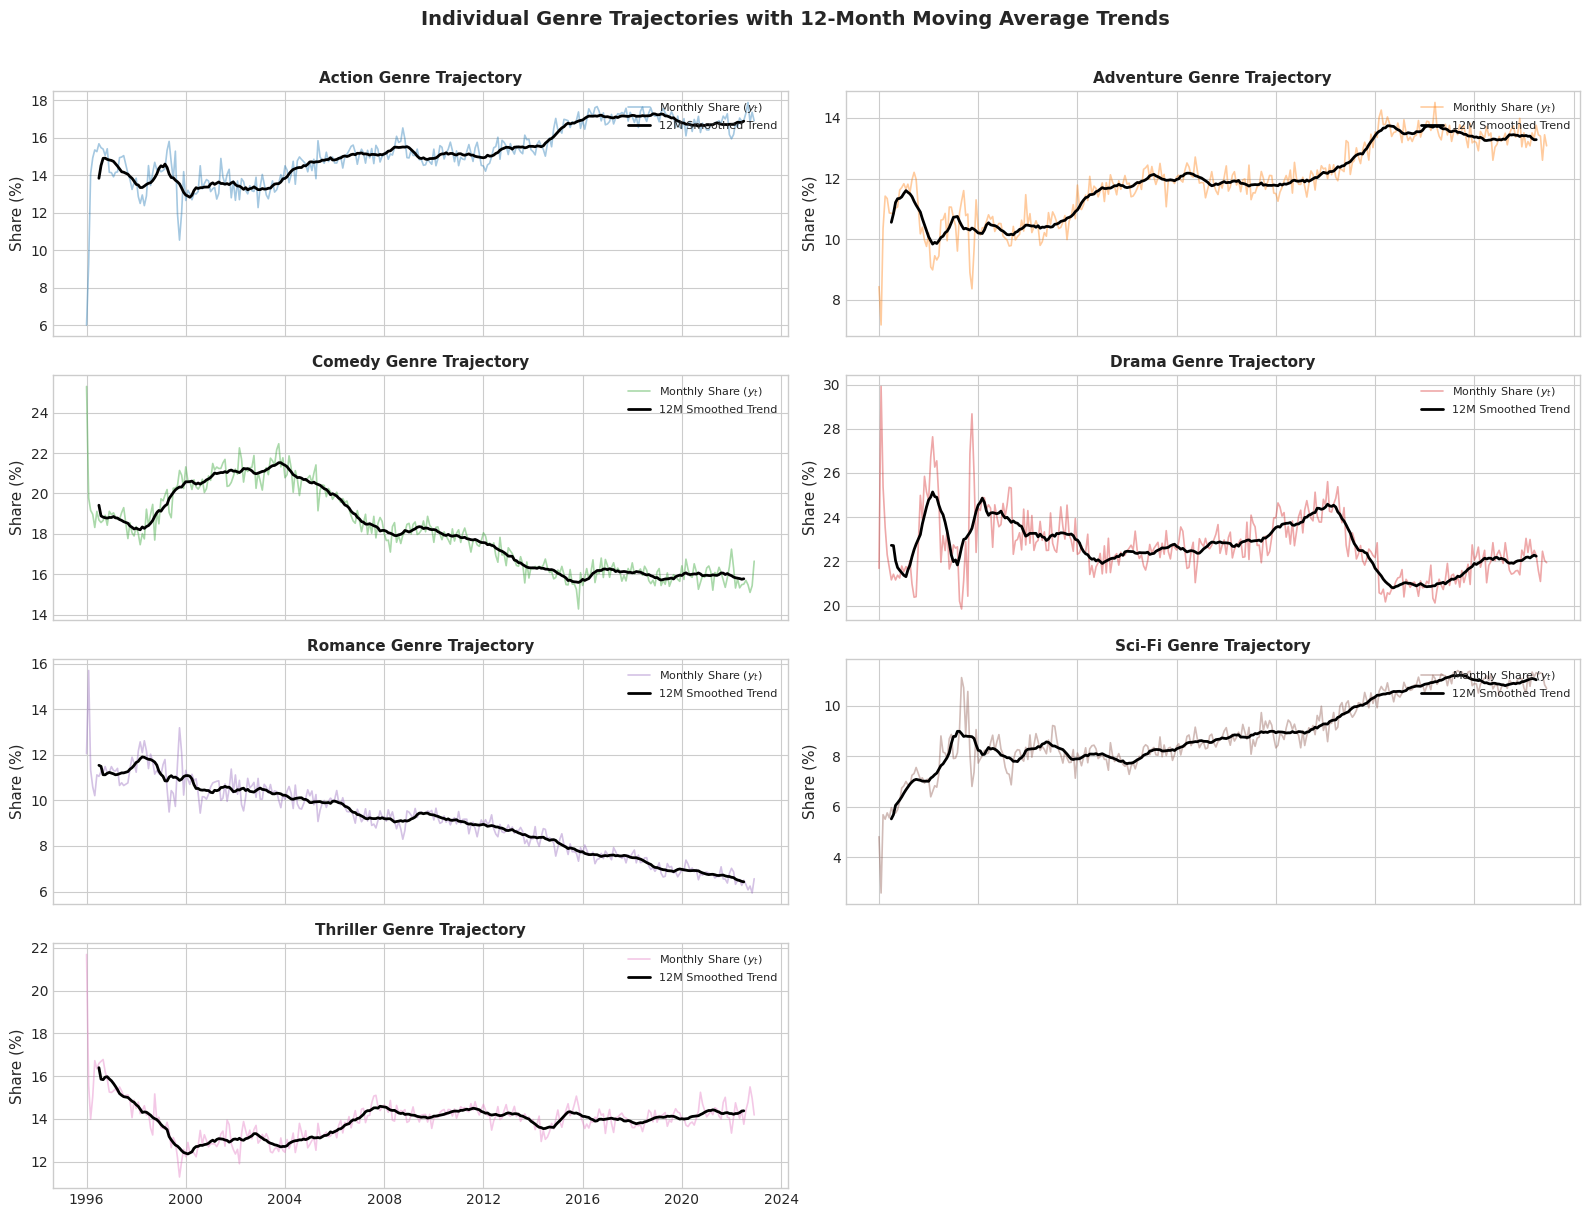

In [10]:
# 3B. Individual Panels with 12-Month Rolling Trend for ALL Genres
fig, axes = plt.subplots(4, 2, figsize=(16, 12), sharex=True)
axes = axes.flatten()

for i, g in enumerate(target_genres):
    axes[i].plot(data_share.index, data_share[g], color=colors[i], alpha=0.4, lw=1.2, label='Monthly Share ($y_t$)')
    axes[i].plot(data_share.index, data_share[g].rolling(12, center=True).mean(), color='black', lw=2.0, label='12M Smoothed Trend')
    axes[i].set_title(f"{g} Genre Trajectory", fontsize=11, fontweight='bold')
    axes[i].set_ylabel("Share (%)")
    axes[i].legend(loc='upper right', fontsize=8)

axes[-1].axis('off')
plt.suptitle("Individual Genre Trajectories with 12-Month Moving Average Trends", y=1.01, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


Generating subseasonal year plots...


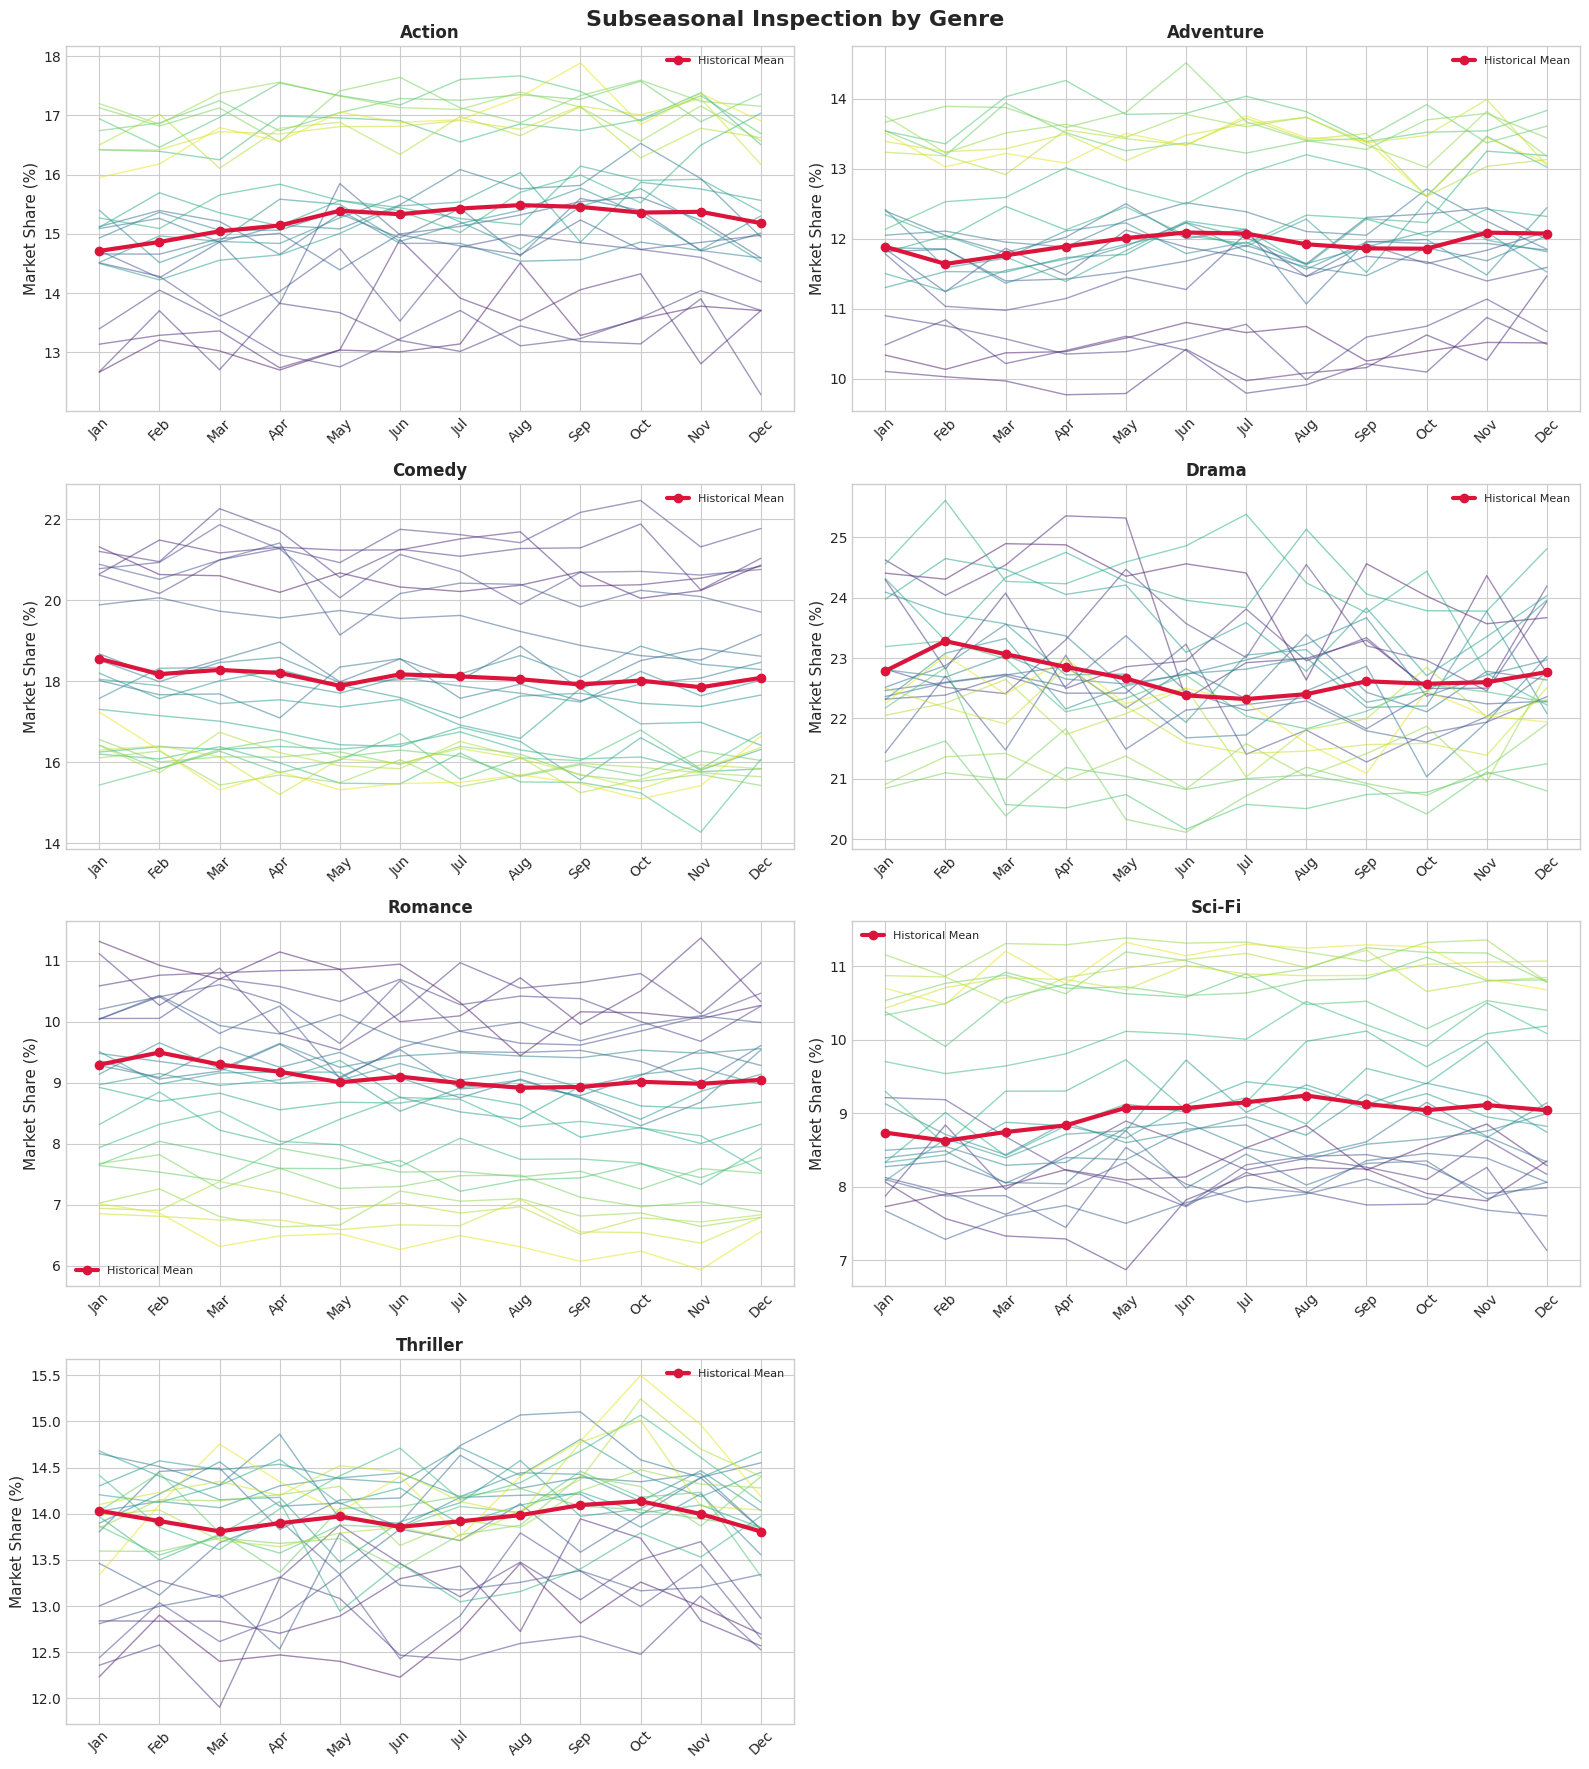

In [11]:
# ------------------------------------------------------------------------------
# By layering the 12 calendar months (Jan to Dec) of each individual year on top
# of each other, we visually evaluate whether seasonal peaks (e.g., Summer/Holiday
# spikes) recur regularly across decades.
# ------------------------------------------------------------------------------
print("\nGenerating subseasonal year plots...")

months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

fig, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.ravel()

def plot_genre_subseasonal(genre, ax):
    df = data_share[[genre]].assign(Year=data_share.index.year, Month=data_share.index.month)

    sample = df[df.Year.between(2000, 2022)]
    palette = sns.color_palette("viridis", sample.Year.nunique())

    for c, yr in zip(palette, sorted(sample.Year.unique())):
        s = sample[sample.Year == yr]
        ax.plot(s.Month, s[genre], color=c, alpha=.5, lw=1)

    mean_profile = df.groupby('Month')[genre].mean()
    ax.plot(mean_profile.index, mean_profile, color='crimson', lw=3, marker='o', label='Historical Mean')

    ax.set_title(genre)
    ax.set_ylabel('Market Share (%)')
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(months, rotation=45)
    ax.legend(fontsize=8)

genres = ['Action', 'Adventure', 'Comedy', 'Drama', 'Romance', 'Sci-Fi', 'Thriller']

for ax, genre in zip(axes, genres): plot_genre_subseasonal(genre, ax)

axes[-1].axis('off')    # Hide 8th panel
plt.suptitle('Subseasonal Inspection by Genre', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

<div style="
background:#1F2937;
padding:12px;
border-left:8px solid #f6d13b;
border-radius:8px;
color:white;
font-size:24px;
font-weight:bold;">

STEP 5 - Time Series Decomposition 📈

</div>


[Step 5] Running STL Decomposition for all 7 target genres...


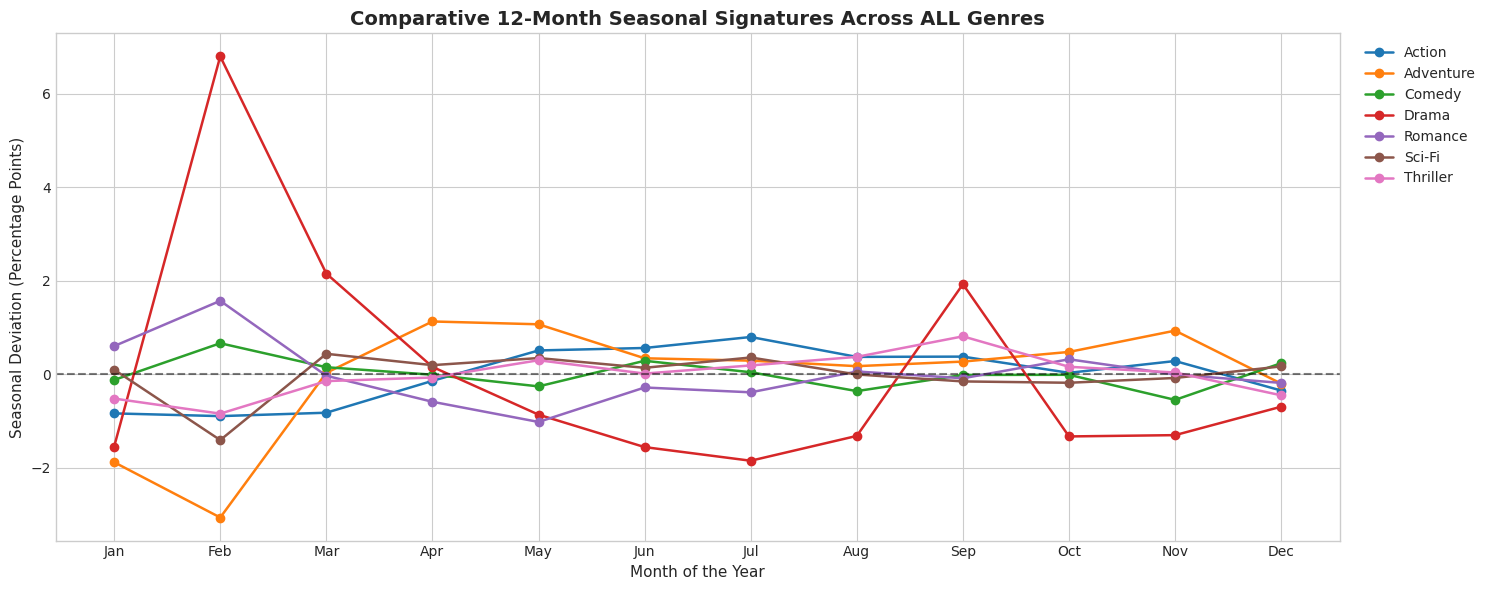

In [13]:
# ------------------------------------------------------------------------------
# Instead of decomposing only one genre, we systematically decompose ALL 7 major
# genres using Seasonal-Trend decomposition using LOESS (STL).
# This isolates Trend (T_t), 12-Month Seasonality (S_t), and Residuals (R_t) for each:
#   y_t = T_t + S_t + R_t
# ------------------------------------------------------------------------------
print("\n[Step 5] Running STL Decomposition for all 7 target genres...")

stl_dict = {}

for g in target_genres:
    stl = STL(data_share[g], period=12, robust=True)
    stl_dict[g] = stl.fit()

# A. Cross-Genre Seasonal Wave Comparison
plt.figure(figsize=(15, 6))
for idx, g in enumerate(target_genres):
    # Plot the first 12 months representing the standard seasonal signature
    seasonal_pattern = stl_dict[g].seasonal.iloc[:12].values
    plt.plot(range(1, 13), seasonal_pattern, marker='o', lw=1.8, color=colors[idx], label=g)

plt.title("Comparative 12-Month Seasonal Signatures Across ALL Genres", fontsize=14, fontweight='bold')
plt.xlabel("Month of the Year")
plt.ylabel("Seasonal Deviation (Percentage Points)")
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

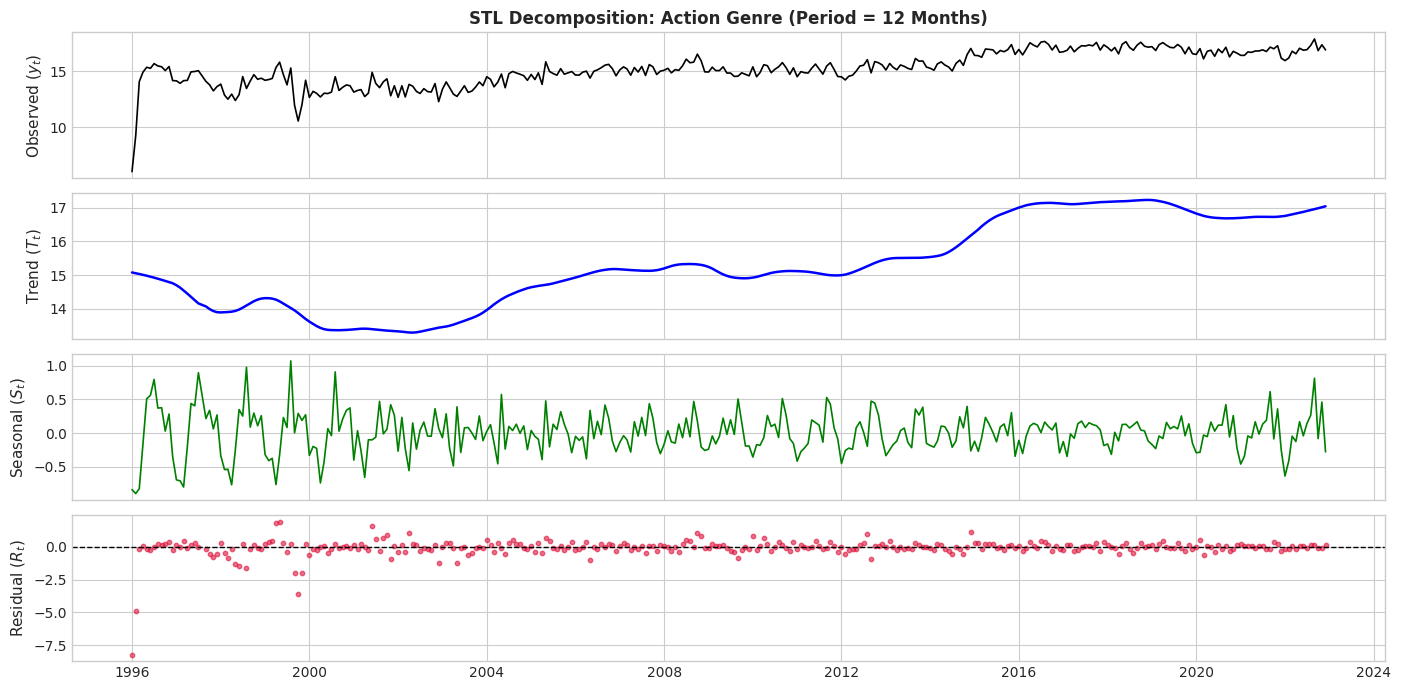

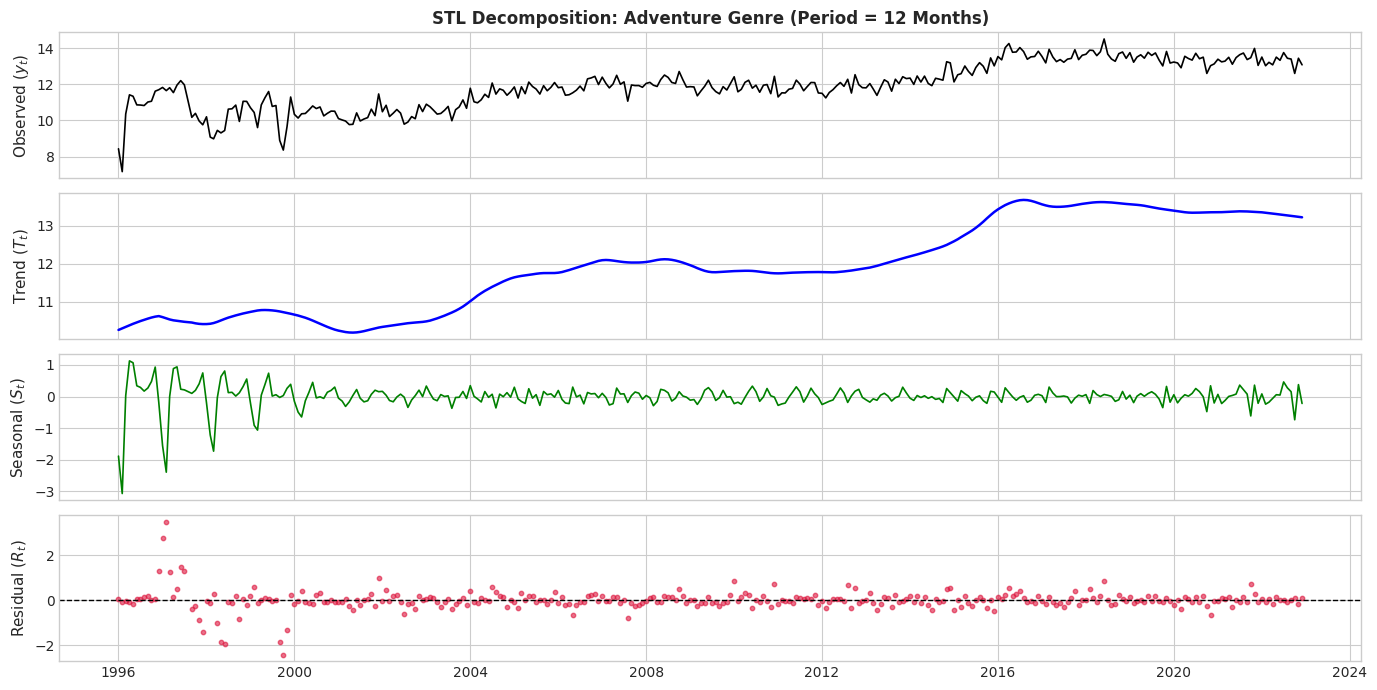

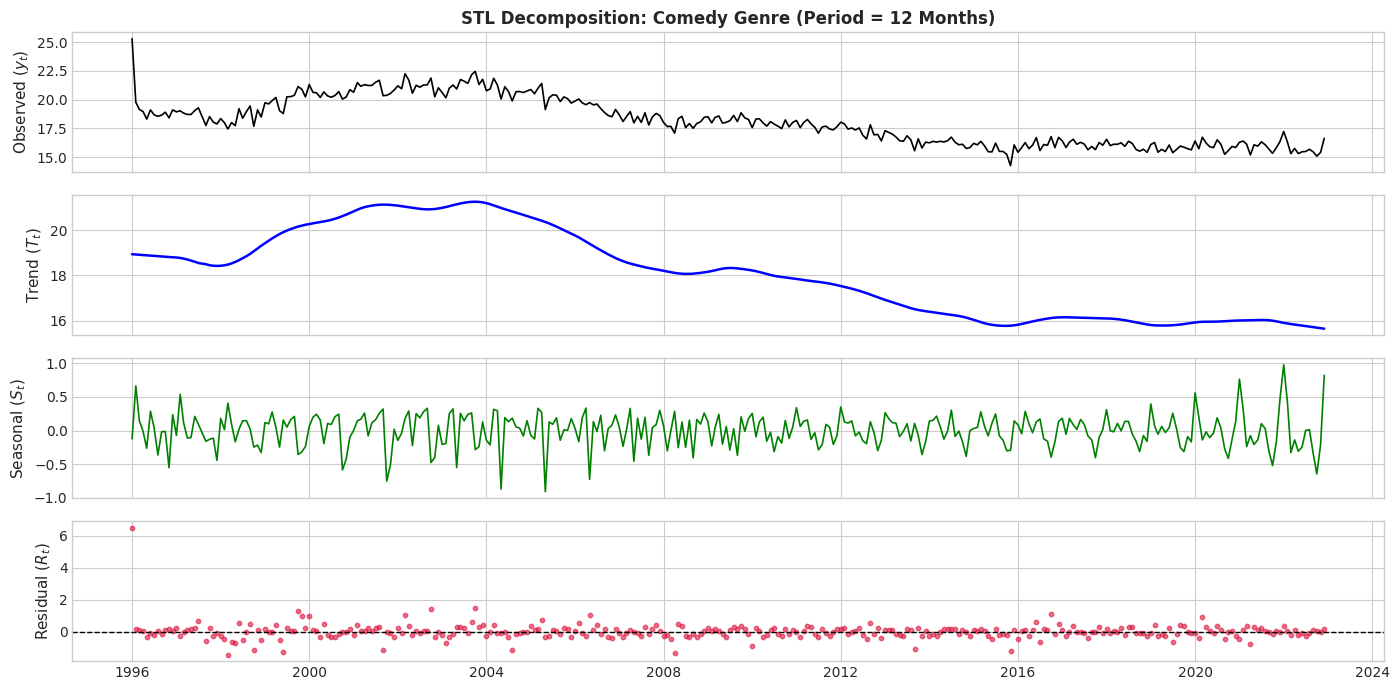

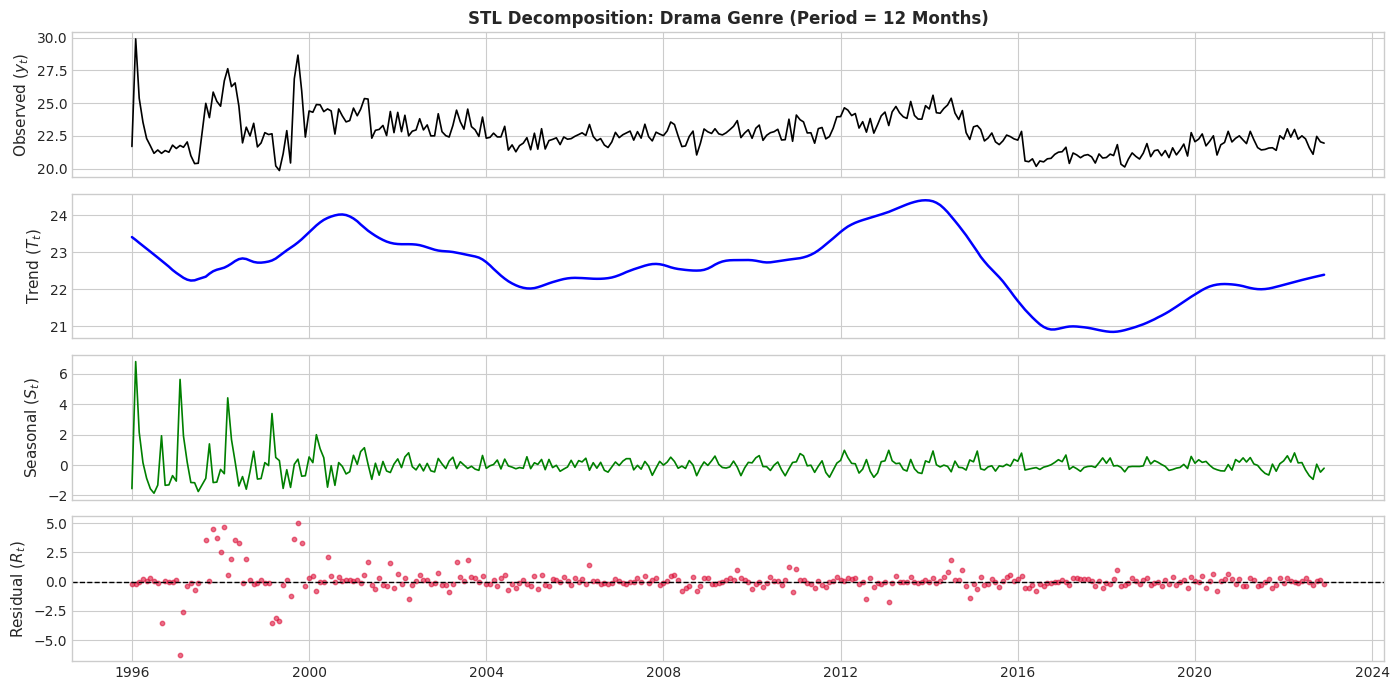

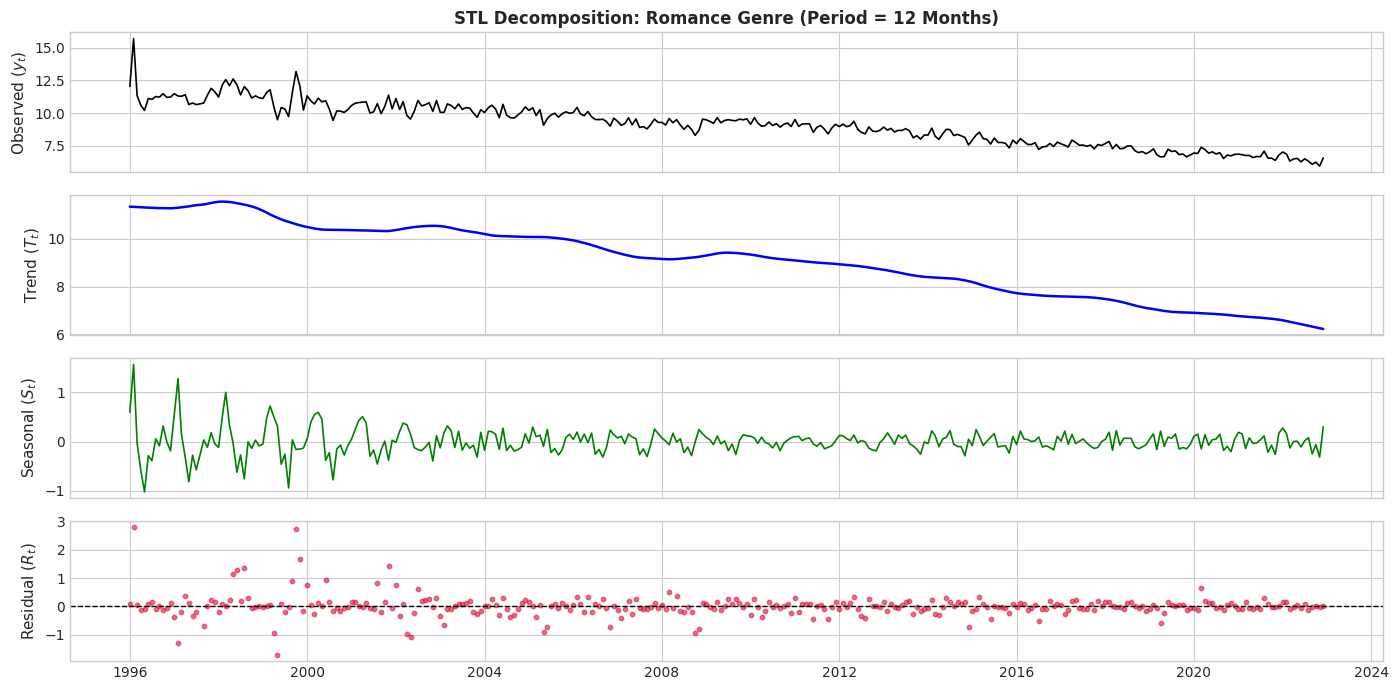

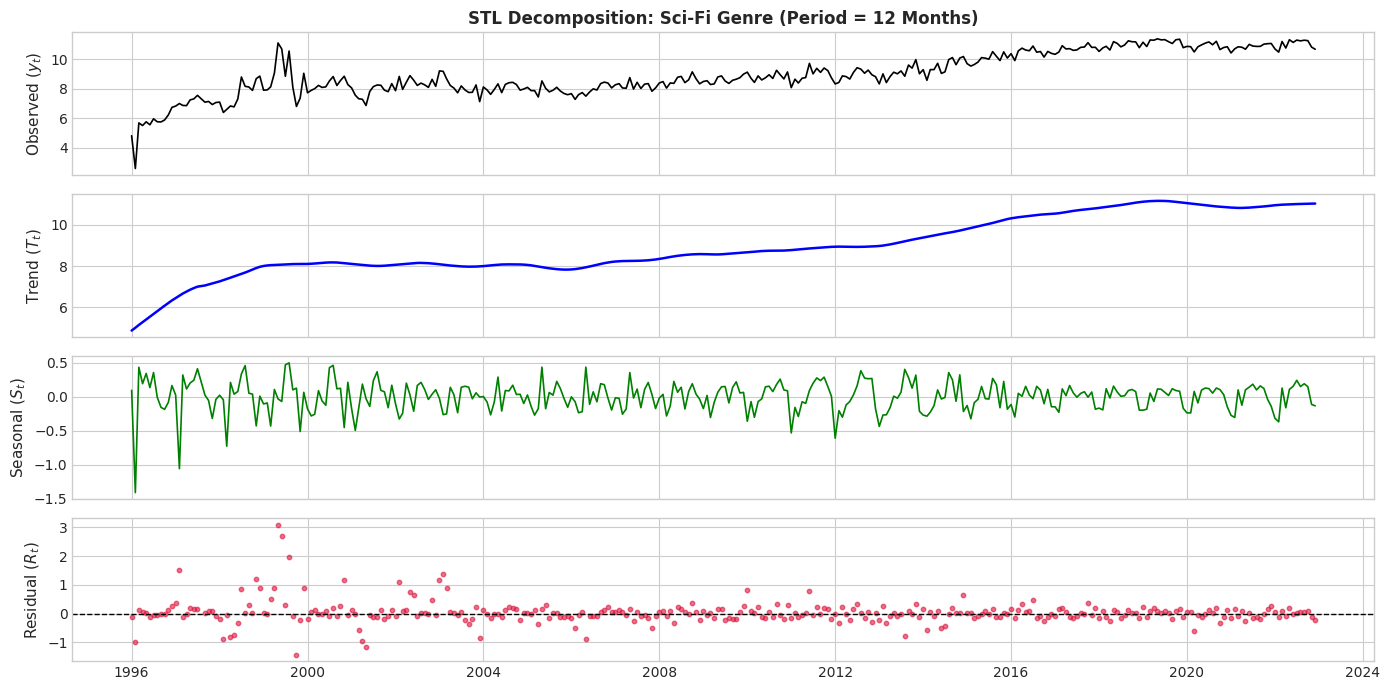

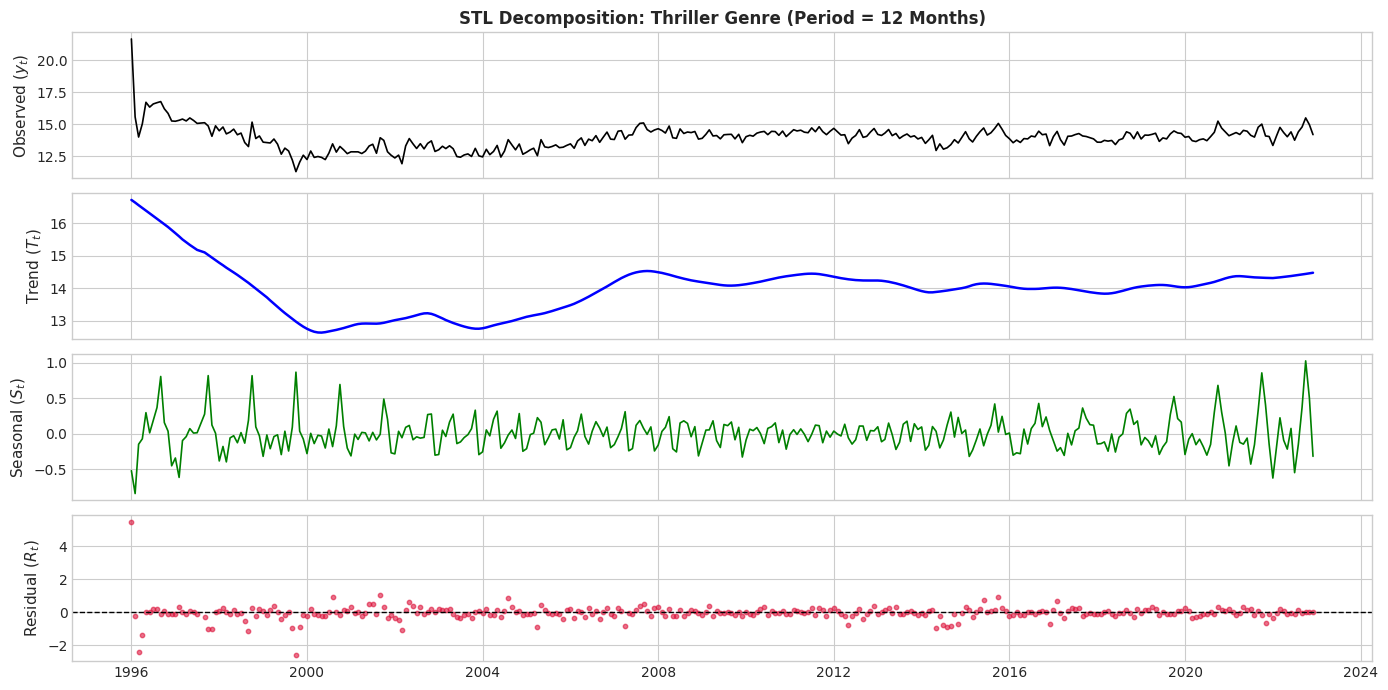

In [14]:
# B. Full 4-Panel Decompositions for EVERY Genre
for g in target_genres:
    res = stl_dict[g]
    fig, axes = plt.subplots(4, 1, figsize=(14, 7), sharex=True)
    
    axes[0].plot(data_share.index, data_share[g], color='black', lw=1.2)
    axes[0].set_ylabel('Observed ($y_t$)')
    axes[0].set_title(f"STL Decomposition: {g} Genre (Period = 12 Months)", fontsize=12, fontweight='bold')
    
    axes[1].plot(data_share.index, res.trend, color='blue', lw=1.8)
    axes[1].set_ylabel('Trend ($T_t$)')
    
    axes[2].plot(data_share.index, res.seasonal, color='green', lw=1.2)
    axes[2].set_ylabel('Seasonal ($S_t$)')
    
    axes[3].scatter(data_share.index, res.resid, color='crimson', alpha=0.6, s=10)
    axes[3].axhline(0, color='black', linestyle='--', lw=1.0)
    axes[3].set_ylabel('Residual ($R_t$)')
    
    plt.tight_layout()
    plt.show()

<div style="
background:#1F2937;
padding:12px;
border-left:8px solid #3bd7f6;
border-radius:8px;
color:white;
font-size:24px;
font-weight:bold;">

STEP 6 - Stationarity Analysis 🔎

</div>

In [15]:
# ------------------------------------------------------------------------------
# STEP 6: FORMAL STATIONARITY TESTING (ADF & KPSS) & ORDER (d, D) DETERMINATION
# ------------------------------------------------------------------------------
# RATIONALE:
# - ADF Test: Tests H0 (unit root / non-stationary). p < 0.05 indicates stationarity.
# - KPSS Test: Tests H0 (series is trend-stationary). p >= 0.05 indicates stationarity.
# Testing both confirms whether first differencing (d=1) and seasonal differencing (D=1)
# are mathematically necessary before modeling in Notebook 3.
# ------------------------------------------------------------------------------
print("\nRunning Augmented Dickey-Fuller (ADF) & KPSS Stationarity Tests...")

stat_records = []

for g in target_genres:
    raw_s = data_share[g]
    diff_s = raw_s.diff().dropna()
    
    # ADF Tests
    adf_p_raw = adfuller(raw_s)[1]
    adf_p_diff = adfuller(diff_s)[1]
    
    # KPSS Tests
    kpss_p_raw = kpss(raw_s, regression='c', nlags='auto')[1]
    kpss_p_diff = kpss(diff_s, regression='c', nlags='auto')[1]
    
    stat_records.append({
        'Genre': g,
        'Raw ADF p': f"{adf_p_raw:.4f}",
        'Raw KPSS p': f"{kpss_p_raw:.4f}",
        'Raw Decision': "Non-Stationary" if adf_p_raw > 0.05 or kpss_p_raw < 0.05 else "Stationary",
        'Diff (d=1) ADF p': f"{adf_p_diff:.4e}",
        'Diff (d=1) KPSS p': f"{kpss_p_diff:.4f}",
        'Conclusion': "Stationary (I(1) Confirmed)" if adf_p_diff < 0.05 and kpss_p_diff >= 0.05 else "Needs Seasonal D=1"
    })

df_stat_results = pd.DataFrame(stat_records)

print("\n" + "="*95)
print("STATIONARITY & ORDER OF INTEGRATION AUDIT LEADERBOARD")
print("="*95)
print(df_stat_results.to_string(index=False))
print("="*95)


Running Augmented Dickey-Fuller (ADF) & KPSS Stationarity Tests...

STATIONARITY & ORDER OF INTEGRATION AUDIT LEADERBOARD
    Genre Raw ADF p Raw KPSS p   Raw Decision Diff (d=1) ADF p Diff (d=1) KPSS p                  Conclusion
   Action    0.4759     0.0100 Non-Stationary       9.4231e-22            0.1000 Stationary (I(1) Confirmed)
Adventure    0.9341     0.0100 Non-Stationary       9.1623e-12            0.1000 Stationary (I(1) Confirmed)
   Comedy    0.8645     0.0100 Non-Stationary       6.1431e-03            0.1000 Stationary (I(1) Confirmed)
    Drama    0.3877     0.0100 Non-Stationary       2.1836e-09            0.1000 Stationary (I(1) Confirmed)
  Romance    0.9101     0.0100 Non-Stationary       2.4626e-20            0.1000 Stationary (I(1) Confirmed)
   Sci-Fi    0.1927     0.0100 Non-Stationary       1.1434e-12            0.1000 Stationary (I(1) Confirmed)
 Thriller    0.0165     0.1000     Stationary       6.4052e-22            0.0520 Stationary (I(1) Confirmed)


<div style="
background:#1F2937;
padding:12px;
border-left:8px solid #3bd7f6;
border-radius:8px;
color:white;
font-size:24px;
font-weight:bold;">

STEP 7 - ACF & PACF Analysis 🔎

</div>


Generating ACF and PACF diagnostics across all genres...


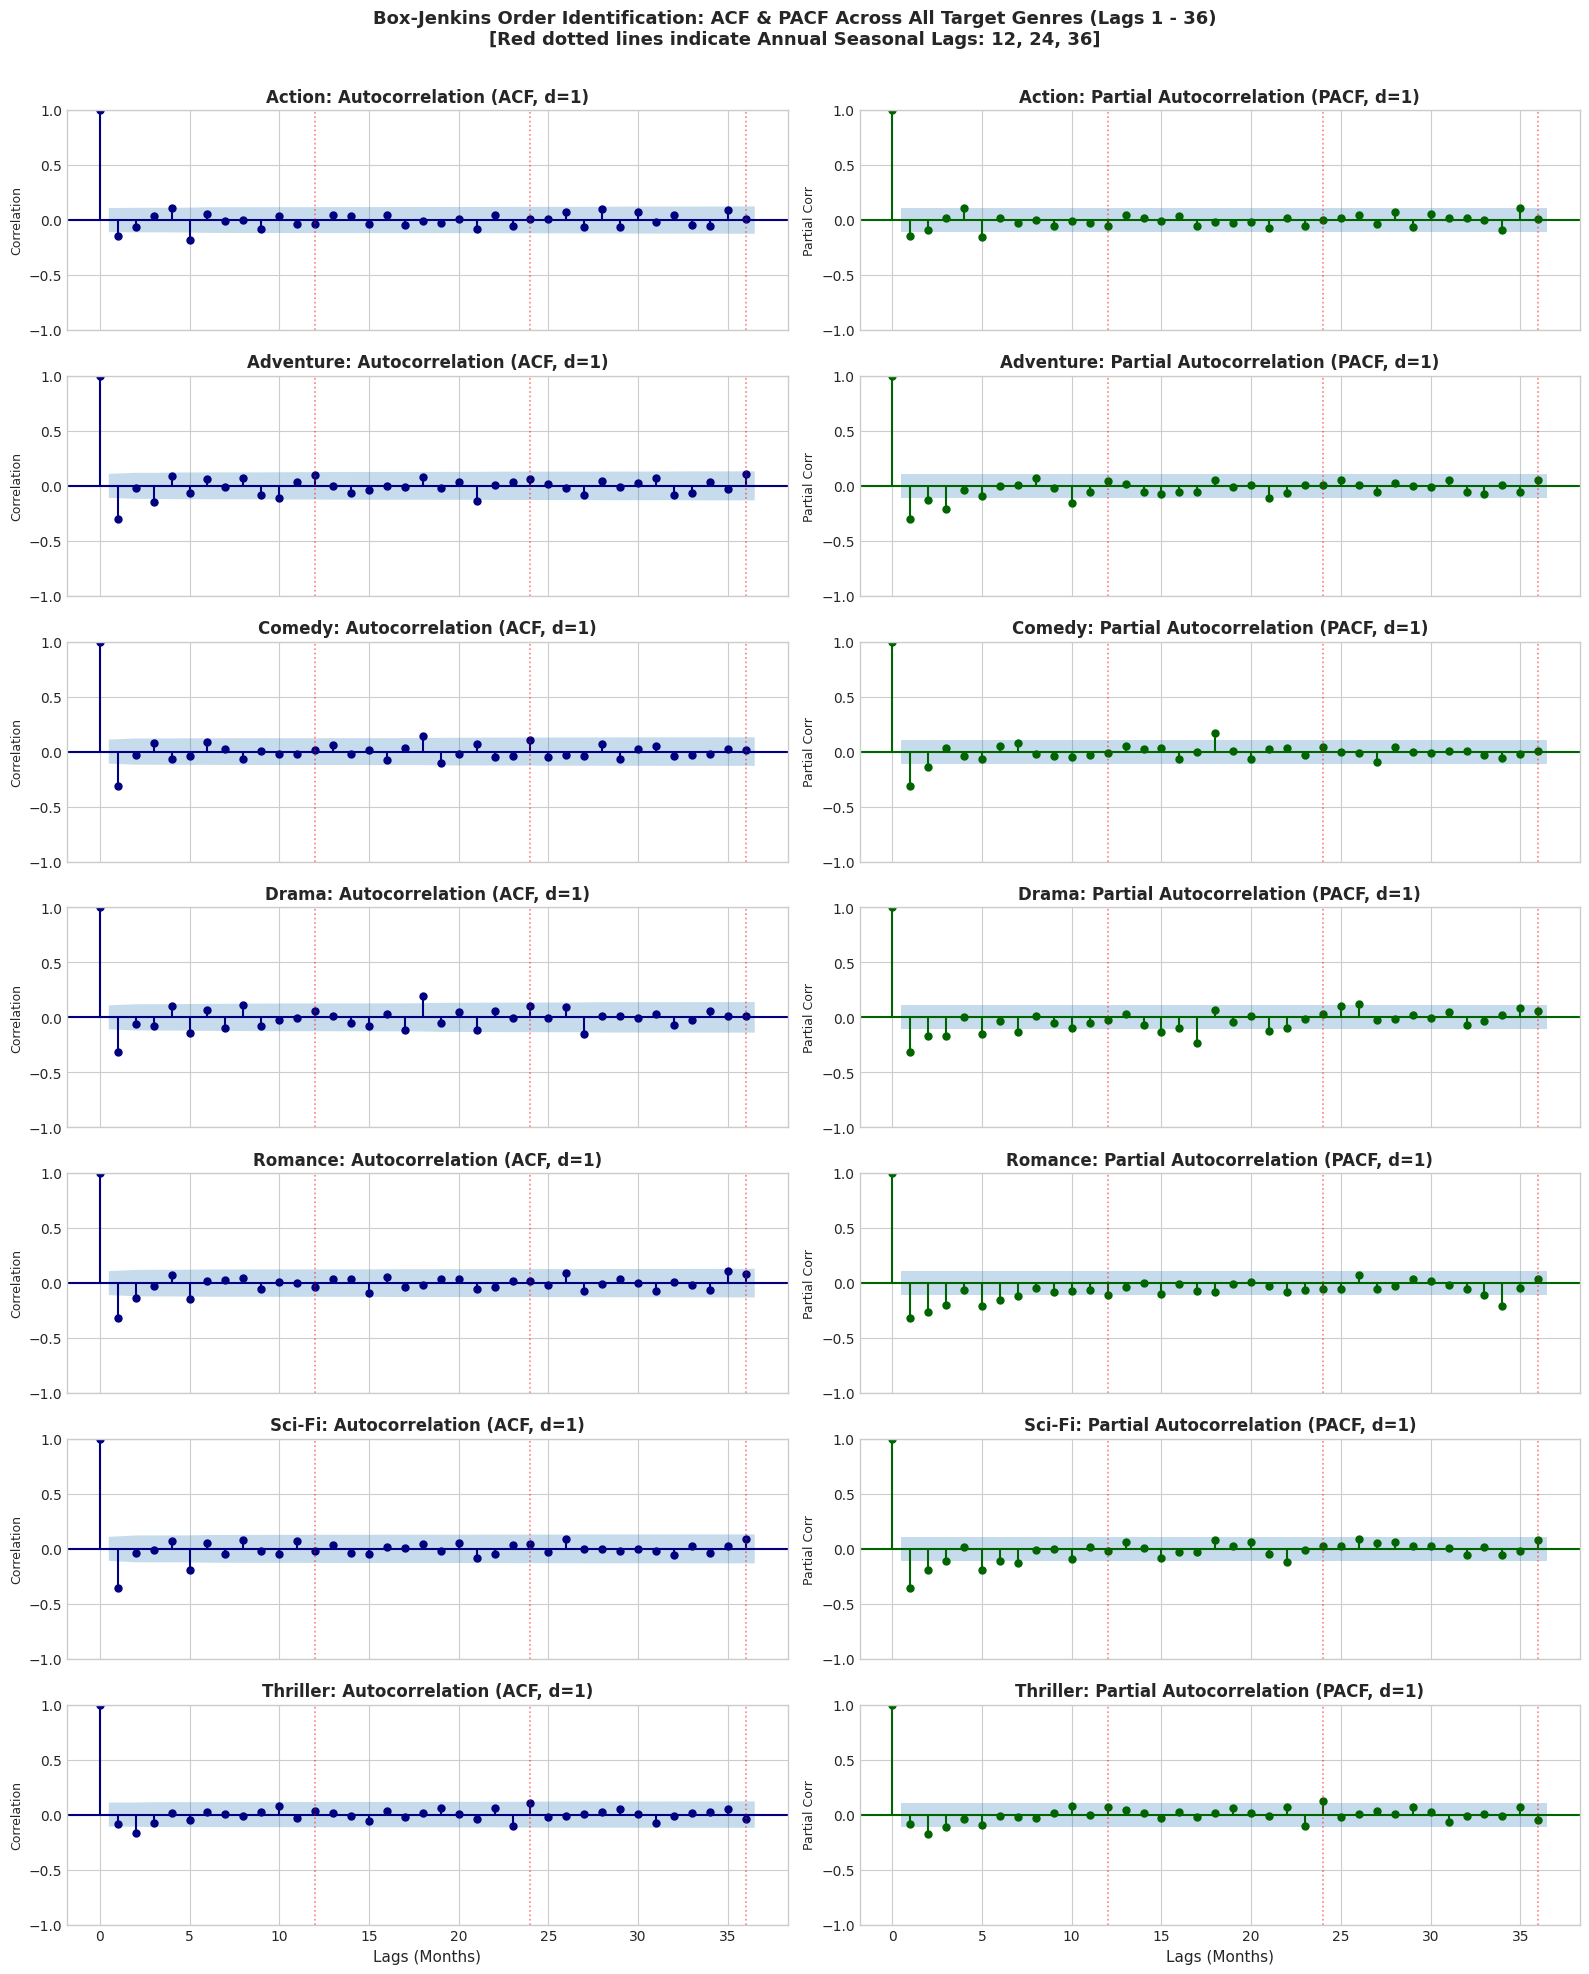

In [ ]:
# ------------------------------------------------------------------------------
# STEP 7: ACF & PACF INSPECTION ACROSS ALL GENRES (BOX-JENKINS IDENTIFICATION)
# ------------------------------------------------------------------------------
# RATIONALE & OBJECTIVE:
# In the Box-Jenkins modeling framework:
# 1. ACF of differenced series (d=1) indicates candidate Moving Average (q) orders
#    and reveals seasonal periodicity (spikes at lag 12, 24, 36).
# 2. PACF of differenced series (d=1) indicates candidate Autoregressive (p) orders.
#
# Inspecting all genres together confirms whether SARIMA(p,1,q)(P,1,Q)[12] 
# is a universal specification across movie genres or if different genres require
# completely different model families.
# ------------------------------------------------------------------------------
print("\nGenerating ACF and PACF diagnostics across all genres...")

n_genres = len(target_genres)
fig, axes = plt.subplots(n_genres, 2, figsize=(16, 2.8 * n_genres), sharex=True)

acf_pacf_findings = []

for i, g in enumerate(target_genres):
    # Take first difference (d=1) to ensure stationarity
    diff_series = data_share[g].diff().dropna()
    
    # Left Column: ACF
    plot_acf(diff_series, lags=36, ax=axes[i, 0], 
             title=f"{g}: Autocorrelation (ACF, d=1)", color='navy', vlines_kwargs={'colors': 'navy'})
    axes[i, 0].set_ylabel("Correlation", fontsize=9)
    
    # Highlight seasonal lags 12, 24, 36 with vertical reference lines 
    for s_lag in [12, 24, 36]:  #(I will change if there is any other pattern)
        axes[i, 0].axvline(s_lag, color='red', linestyle=':', alpha=0.5, lw=1.2)
    
    # Right Column: PACF
    plot_pacf(diff_series, lags=36, ax=axes[i, 1], 
              title=f"{g}: Partial Autocorrelation (PACF, d=1)", color='darkgreen', vlines_kwargs={'colors': 'darkgreen'})
    axes[i, 1].set_ylabel("Partial Corr", fontsize=9)
    for s_lag in [12, 24, 36]:  #(I will change if there is any other pattern)
        axes[i, 1].axvline(s_lag, color='red', linestyle=':', alpha=0.5, lw=1.2)

# Set common X-axis labels on bottom row
axes[-1, 0].set_xlabel("Lags (Months)", fontsize=11)
axes[-1, 1].set_xlabel("Lags (Months)", fontsize=11)

plt.suptitle("Box-Jenkins Order Identification: ACF & PACF Across All Target Genres (Lags 1 - 36)\n"
             "[Red dotted lines indicate Annual Seasonal Lags: 12, 24, 36]", 
             y=1.005, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [22]:
# ------------------------------------------------------------------------------
# STEP 8B: TABULAR AUDIT OF SIGNIFICANT LAGS ACROSS ALL GENRES
# ------------------------------------------------------------------------------
from statsmodels.tsa.stattools import acf, pacf

audit_rows = []
alpha = 0.05
# 95% Confidence interval threshold: ~ 1.96 / sqrt(N)
conf_bound = 1.96 / np.sqrt(len(data_share) - 1)

for g in target_genres:
    diff_s = data_share[g].diff().dropna()
    acf_vals = acf(diff_s, nlags=36)
    pacf_vals = pacf(diff_s, nlags=36)
    
    # Check non-seasonal lags (1-3)
    sig_p = [lag for lag in [1, 2, 3] if abs(pacf_vals[lag]) > conf_bound]
    sig_q = [lag for lag in [1, 2, 3] if abs(acf_vals[lag]) > conf_bound]
    
    # Check annual seasonal lags (12, 24, 36)
    sig_seasonal = [lag for lag in [12, 24, 36] if abs(acf_vals[lag]) > conf_bound]
    
    audit_rows.append({
        'Genre': g,
        'Significant Short-Term AR (p lags)': sig_p if sig_p else 'None',
        'Significant Short-Term MA (q lags)': sig_q if sig_q else 'None',
        'Significant Seasonal Lags (ACF)': sig_seasonal if sig_seasonal else 'Weak',
        'Suggested SARIMA Specification': f"({max(sig_p, default=1)}, 1, {max(sig_q, default=1)})(1, 1, 1)[12]"
    })

df_audit = pd.DataFrame(audit_rows)
print("\n" + "="*100)
print("BOX-JENKINS MODEL SPECIFICATION AUDIT ACROSS ALL GENRES")
print("="*100)
print(df_audit.to_string(index=False))
print("="*100)


BOX-JENKINS MODEL SPECIFICATION AUDIT ACROSS ALL GENRES
    Genre Significant Short-Term AR (p lags) Significant Short-Term MA (q lags) Significant Seasonal Lags (ACF) Suggested SARIMA Specification
   Action                                [1]                                [1]                            Weak         (1, 1, 1)(1, 1, 1)[12]
Adventure                          [1, 2, 3]                             [1, 3]                            Weak         (3, 1, 3)(1, 1, 1)[12]
   Comedy                             [1, 2]                                [1]                            Weak         (2, 1, 1)(1, 1, 1)[12]
    Drama                          [1, 2, 3]                                [1]                            Weak         (3, 1, 1)(1, 1, 1)[12]
  Romance                          [1, 2, 3]                             [1, 2]                            Weak         (3, 1, 2)(1, 1, 1)[12]
   Sci-Fi                          [1, 2, 3]                                [1]      

`In the end, we will specify the minimum d value that makes series stationary (here it is 1) and choose p and q values that will have the lowest AIC/BIC (validation performance) in the modelling phase next` <br>
`We have no options in Search GRID for P,D and Q values as all `